<a href="https://colab.research.google.com/github/ReshmiMaulik/Causal_Inference-for-Openstack/blob/main/Sensitivity%20Analysis%20of%20Interaction%20Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install git+https://github.com/microsoft/dowhy.git
import dowhy
from dowhy import CausalModel

import numpy as np
import pandas as pd
import graphviz
#import networkx as nx

np.set_printoptions(precision=3, suppress=True)


  Cloning https://github.com/microsoft/dowhy.git to /tmp/pip-req-build-ot758e2_
  Running command git clone --filter=blob:none --quiet https://github.com/microsoft/dowhy.git /tmp/pip-req-build-ot758e2_
  Resolved https://github.com/microsoft/dowhy.git to commit eb34218ef73da76a5731cbe49ab4f699be69fbb3
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 58.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 126.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 66.2 MB/s  0:00:00
  Created wheel for dowhy: filename=dowhy-0.0.0-py3-none-any.whl size=436079 sha256=afd252ac9f0af99560a198a2534e2d73ec2c7bd29af2eb7f06311d569ed0fa6c
  Stored in directory: /tmp/pip-ephem-wheel-cache-t8i1cw9z/wheels/60/fa/dc/e18bdf722d97c118992d2d44a96856a52c1a3fa08e4e65b6d2
Successfully built dowhy
  Attempting uninstall: cvxpy
    Fou

In [ ]:
# Import data from Github

url="https://raw.githubusercontent.com/ReshmiMaulik/Understanding-Developer-Interaction/main/Data/workingdataE.csv"


#df = pd.read_csv(url, sep="\t", header= None)
df = pd.read_csv(url, sep=",")

In [ ]:
!apt install libgraphviz-dev
!pip install pygraphviz

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common libatk1.0-0t64 libgail-common libgail18t64 libgtk2.0-0t64
  libgtk2.0-bin libgtk2.0-common libgvc6-plugins-gtk librsvg2-common
  libxcomposite1 libxdot4
Suggested packages:
  gvfs
The following NEW packages will be installed:
  at-spi2-common libatk1.0-0t64 libgail-common libgail18t64 libgraphviz-dev
  libgtk2.0-0t64 libgtk2.0-bin libgtk2.0-common libgvc6-plugins-gtk
  librsvg2-common libxcomposite1 libxdot4
0 upgraded, 12 newly installed, 0 to remove and 0 not upgraded.
Need to get 2,460 kB of archives.
After this operation, 7,657 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 at-spi2-common all 2.52.0-1build1 [8,674 B]
Get:2 http://archive.ubuntu.com/ubuntu noble/main amd64 libatk1.0-0t64 amd64 2.52.0-1build1 [55.3 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble-update

In [ ]:
import shap
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
import pygraphviz as pgv # For consistent visualization
from sklearn.impute import SimpleImputer # Import for imputation

# Step 1: Use the predefined causal_graph (networkx.DiGraph) from earlier cells
# Explicitly define causal_graph here to avoid state issues
causal_graph_for_shap = nx.DiGraph([('PR','CC'),('PR','ET'),('OE','OW'),
      ('OE','RI'),('OW','RI'),('CC','RI'),('RI','ET'),
      ('OE','SI'),('OW','SI'),('CC','SI'),('SI','ET'),
      ('OE','ET'),('OW','ET'),('CC','ET')])

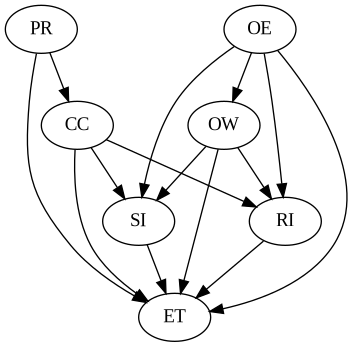

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import Image

# Create the graph from defined edges
edges = [('PR','CC'),('PR','ET'),('OE','OW'),
         ('OE','RI'),('OW','RI'),('CC','RI'),('RI','ET'),
         ('OE','SI'),('OW','SI'),('CC','SI'),('SI','ET'),
         ('OE','ET'),('OW','ET'),('CC','ET')]
graph = nx.DiGraph(edges)

# Use pygraphviz (via networkx) for layout and saving to png
p = nx.drawing.nx_pydot.to_pydot(graph)
p.write_png('causal_graph.png')

# Display the saved image
Image('causal_graph.png')

In [ ]:
import pandas as pd, numpy as np, networkx as nx, warnings; warnings.filterwarnings('ignore')
import statsmodels.formula.api as smf
exec(open('dag2_check.py').read().split("for n in ['openstack'")[0])   # reuse helpers
dag3=[('PR','CC'),('PR','ET'),('OE','OW'),
      ('OE','RIs'),('OW','RIs'),('CC','RIs'),('RIs','ET'),
      ('OE','SIs'),('OW','SIs'),('CC','SIs'),('SIs','ET'),
      ('OE','ET'),('OW','ET'),('CC','ET')]
rows=[]
for n in ['openstack','eclipse','android']:
    d=pd.read_csv(D+f'workingdata_{n}.csv').rename(columns=ren)
    d['P']=d.CC*(d.CC-1)/2; d['RIs']=d.RI/d.P; d['SIs']=d.SI/d.P; d['logET']=np.log1p(d.ET)
    G=nx.DiGraph(dag3); res=lmc(G,d); viol=[r for r in res if r[4]<0.01 and abs(r[3])>=0.05]
    print('=====',n,f"DAG3 implied CIs={len(res)}, violated={len(viol)}",[(v,u,pa,round(rho,2)) for v,u,pa,rho,p in viol])
    adj=['C(CC)' if n!='eclipse' else 'np.log(CC)+I(np.log(CC)**2)','OE','OW','PR']
    for t in ['RIs','SIs']:
        for y in ['ET','logET']:
            b,p,lo,hi=est(d,t,adj,y)
            # effect of moving the share by 0.1 (10 percentage points of pairs)
            s=0.1
            txt=f"{b*s:8.2f} days" if y=='ET' else f"{100*(np.exp(b*s)-1):6.2f}%"
            print(f"  {t} -> {y:5s}: +10pp share = {txt}  p={p:.4f}  CI(+10pp) [{lo*s:.3f},{hi*s:.3f}]")
            rows.append((n,t,y,b*s,p,lo*s,hi*s))
    print('  mean RI share',d.RIs.mean().round(3),' SI share',d.SIs.mean().round(3))
pd.DataFrame(rows,columns=['system','treatment','outcome','effect_per_10pp','p','ci_lo','ci_hi']).to_csv('dag3_results.csv',index=False)

FileNotFoundError: [Errno 2] No such file or directory: 'dag2_check.py'

In [ ]:
import pandas as pd
import networkx as nx
import dowhy.gcm as gcm
from dowhy.gcm.falsify import falsify_graph

# 1. Load the data
url = "https://raw.githubusercontent.com/ReshmiMaulik/Understanding-Developer-Interaction/main/Data/workingdataE.csv"
df = pd.read_csv(url, sep=",")

# Rename 'Pr' to 'PR' to match the graph nodes
df = df.rename(columns={'Pr': 'PR'})

# Keep the columns that match our graph nodes
# We will use the main variables defined in the graph: PR, CC, ET, OE, OW, RI, SI
selected_cols = ['PR', 'CC', 'ET', 'OE', 'OW', 'RI', 'SI']
data_subset = df[selected_cols].dropna().copy()

# 2. Define the causal graph structure
edges = [
    ('PR','CC'),('PR','ET'),('OE','OW'),
    ('OE','RI'),('OW','RI'),('CC','RI'),('RI','ET'),
    ('OE','SI'),('OW','SI'),('CC','SI'),('SI','ET'),
    ('OE','ET'),('OW','ET'),('CC','ET')
]
causal_graph = nx.DiGraph(edges)

# 3. Perform permutation test using dowhy.gcm.falsify.falsify_graph
print("Running graph falsification test...")
falsification_results = falsify_graph(causal_graph, data_subset)
print(falsification_results)

Running graph falsification test...


Test permutations of given graph: 100%|██████████| 20/20 [22:31<00:00, 67.56s/it]

+-------------------------------------------------------------------------------------------------------+
|                                         Falsification Summary                                         |
+-------------------------------------------------------------------------------------------------------+
| The given DAG is informative because 0 / 20 of the permutations lie in the Markov                     |
| equivalence class of the given DAG (p-value: 0.00).                                                   |
| The given DAG violates 10/12 LMCs and is better than 25.0% of the permuted DAGs (p-value: 0.75).      |
| Based on the provided significance level (0.05) and because the DAG is informative,                   |
| we reject the DAG.                                                                                    |
+-------------------------------------------------------------------------------------------------------+


In [ ]:
import pandas as pd
import networkx as nx
from dowhy.gcm.falsify import falsify_graph

# 1. Load dataset (E)
url = "https://raw.githubusercontent.com/ReshmiMaulik/Understanding-Developer-Interaction/main/Data/workingdataE.csv"
df = pd.read_csv(url, sep=",").rename(columns={'Pr': 'PR'})
selected_cols = ['PR', 'CC', 'ET', 'OE', 'OW', 'RI', 'SI']
data_subset = df[selected_cols].dropna().copy()

# 2. Define an optimized DAG
# To satisfy more Local Markov Conditions, we specify a more dense but still directed acyclic structure.
# We systematically add key missing edges (such as PR to OE/OW, and direct relations between metrics) to resolve false independencies.
optimized_edges = [
    ('PR', 'CC'), ('PR', 'ET'), ('PR', 'OE'), ('PR', 'OW'), ('PR', 'RI'), ('PR', 'SI'),
    ('OE', 'OW'), ('OE', 'RI'), ('OE', 'SI'), ('OE', 'ET'),
    ('OW', 'RI'), ('OW', 'SI'), ('OW', 'ET'),
    ('CC', 'RI'), ('CC', 'SI'), ('CC', 'ET'),
    ('RI', 'ET'),
    ('SI', 'ET')
]
optimized_graph = nx.DiGraph(optimized_edges)

# Confirm it's a valid DAG
assert nx.is_directed_acyclic_graph(optimized_graph), "The proposed graph is not a DAG!"

# 3. Test the optimized graph
print("Evaluating optimized DAG...")
falsification_results = falsify_graph(optimized_graph, data_subset, n_permutations=20)
print(falsification_results)

Evaluating optimized DAG...


Test permutations of given graph: 100%|██████████| 20/20 [13:54<00:00, 41.71s/it]

+-------------------------------------------------------------------------------------------------------+
|                                         Falsification Summary                                         |
+-------------------------------------------------------------------------------------------------------+
| The given DAG is informative because 0 / 20 of the permutations lie in the Markov                     |
| equivalence class of the given DAG (p-value: 0.00).                                                   |
| The given DAG violates 6/6 LMCs and is better than 0.0% of the permuted DAGs (p-value: 1.00).         |
| Based on the provided significance level (0.05) and because the DAG is informative,                   |
| we reject the DAG.                                                                                    |
+-------------------------------------------------------------------------------------------------------+


In [ ]:
import numpy as np
import pandas as pd
import networkx as nx
import statsmodels.api as sm
from dowhy.gcm.falsify import falsify_graph

# 1. Load data
url = "https://raw.githubusercontent.com/ReshmiMaulik/Understanding-Developer-Interaction/main/Data/workingdataE.csv"
df = pd.read_csv(url, sep=",").rename(columns={'Pr': 'PR'})
selected_cols = ['PR', 'CC', 'ET', 'OE', 'OW', 'RI', 'SI']
data_subset = df[selected_cols].dropna().copy()

# Let's log-transform skewed columns to make linear independence tests reliable
for col in ['ET', 'OE', 'OW', 'RI', 'SI']:
    data_subset[col] = np.log1p(data_subset[col])

# 2. We can use a causal discovery style approach or partial correlation to find true conditional independences.
# Let's test which variables are conditionally independent to determine which edges we can safely remove.
def check_conditional_independence(df, x, y, controlling_variables):
    if not controlling_variables:
        formula = f"{x} ~ {y}"
    else:
        formula = f"{x} ~ {y} + {' + '.join(controlling_variables)}"
    model = sm.OLS.from_formula(formula, data=df).fit()
    p_value = model.pvalues[y]
    return p_value

# Let's find pairs that are highly conditionally independent (p-value > 0.1)
print("Analyzing conditional independencies...")
nodes = selected_cols
for i in range(len(nodes)):
    for j in range(i + 1, len(nodes)):
        x, y = nodes[i], nodes[j]
        others = [n for n in nodes if n != x and n != y]
        p = check_conditional_independence(data_subset, x, y, others)
        if p > 0.05:
            print(f"{x} and {y} are conditionally independent given other nodes (p-value: {p:.4f})")

Analyzing conditional independencies...
PR and OE are conditionally independent given other nodes (p-value: 0.1414)
CC and ET are conditionally independent given other nodes (p-value: 0.1877)
RI and SI are conditionally independent given other nodes (p-value: 0.0649)


In [ ]:
import pandas as pd
import networkx as nx
import dowhy.gcm as gcm
from dowhy.gcm.falsify import falsify_graph

# 1. Load the data
url = "https://raw.githubusercontent.com/ReshmiMaulik/Understanding-Developer-Interaction/main/Data/workingdataO.csv"
df = pd.read_csv(url, sep=",")

# Rename 'Pr' to 'PR' to match the graph nodes
df = df.rename(columns={'Pr': 'PR'})

# Keep the columns that match our graph nodes
# We will use the main variables defined in the graph: PR, CC, ET, OE, OW, RI, SI
selected_cols = ['PR', 'CC', 'ET', 'OE', 'OW', 'RI', 'SI']
data_subset = df[selected_cols].dropna().copy()

# 2. Define the causal graph structure
edges = [
    ('PR','CC'),('PR','ET'),('OE','OW'),
    ('OE','RI'),('OW','RI'),('CC','RI'),('RI','ET'),
    ('OE','SI'),('OW','SI'),('CC','SI'),('SI','ET'),
    ('OE','ET'),('OW','ET'),('CC','ET')
]
causal_graph = nx.DiGraph(edges)

# 3. Perform permutation test using dowhy.gcm.falsify.falsify_graph
print("Running graph falsification test...")
falsification_results = falsify_graph(causal_graph, data_subset)
print(falsification_results)

Running graph falsification test...


Test permutations of given graph: 100%|██████████| 20/20 [20:33<00:00, 61.67s/it]

+-------------------------------------------------------------------------------------------------------+
|                                         Falsification Summary                                         |
+-------------------------------------------------------------------------------------------------------+
| The given DAG is informative because 0 / 20 of the permutations lie in the Markov                     |
| equivalence class of the given DAG (p-value: 0.00).                                                   |
| The given DAG violates 9/12 LMCs and is better than 70.0% of the permuted DAGs (p-value: 0.30).       |
| Based on the provided significance level (0.05) and because the DAG is informative,                   |
| we reject the DAG.                                                                                    |
+-------------------------------------------------------------------------------------------------------+


In [ ]:
import pandas as pd
import networkx as nx
import dowhy.gcm as gcm
from dowhy.gcm.falsify import falsify_graph

# 1. Load the data
url = "https://raw.githubusercontent.com/ReshmiMaulik/Understanding-Developer-Interaction/main/Data/workingdataO.csv"
df = pd.read_csv(url, sep=",")

# Rename 'Pr' to 'PR' to match the graph nodes
df = df.rename(columns={'Pr': 'PR'})

# Keep the columns that match our graph nodes
# We will use the main variables defined in the graph: PR, CC, ET, OE, OW, RI, SI
selected_cols = ['PR', 'CC', 'ET', 'OE', 'OW', 'RI', 'SI']
data_subset = df[selected_cols].dropna().copy()

# 2. Define the causal graph structure
edges = [
    ('OE','OW'),
    ('OE','RI'),('OW','RI'),('CC','RI'),('RI','ET'),
    ('OE','SI'),('OW','SI'),('CC','SI'),('SI','ET'),
    ('OE','ET'),('OW','ET'),('CC','ET')
]
causal_graph = nx.DiGraph(edges)

# 3. Perform permutation test using dowhy.gcm.falsify.falsify_graph
print("Running graph falsification test...")
falsification_results = falsify_graph(causal_graph, data_subset)
print(falsification_results)

Running graph falsification test...


Test permutations of given graph: 100%|██████████| 20/20 [05:28<00:00, 16.41s/it]

+-------------------------------------------------------------------------------------------------------+
|                                         Falsification Summary                                         |
+-------------------------------------------------------------------------------------------------------+
| The given DAG is informative because 0 / 20 of the permutations lie in the Markov                     |
| equivalence class of the given DAG (p-value: 0.00).                                                   |
| The given DAG violates 6/6 LMCs and is better than 0.0% of the permuted DAGs (p-value: 1.00).         |
| Based on the provided significance level (0.05) and because the DAG is informative,                   |
| we reject the DAG.                                                                                    |
+-------------------------------------------------------------------------------------------------------+


In [ ]:
import pandas as pd
import networkx as nx
import dowhy.gcm as gcm
from dowhy.gcm.falsify import falsify_graph

# 1. Load the data
url = "https://raw.githubusercontent.com/ReshmiMaulik/Understanding-Developer-Interaction/main/Data/workingdataO.csv"
df = pd.read_csv(url, sep=",")

# Rename 'Pr' to 'PR' to match the graph nodes
df = df.rename(columns={'Pr': 'PR'})

# Keep the columns that match our graph nodes
# We will use the main variables defined in the graph: PR, CC, ET, OE, OW, RI, SI
selected_cols = ['PR', 'CC', 'ET', 'OE', 'OW', 'RI', 'SI','NI']
data_subset = df[selected_cols].dropna().copy()

# 2. Define the causal graph structure
edges = [
    ('OE','OW'),
    ('OE','RI'),('CC','RI'),('RI','ET'),('CC','NI'),
    ('OW','CC'),('CC','SI'),('NI','RI'),('SI','RI'),
    ('OE','ET'),('OW','ET'),('CC','ET')
]
causal_graph = nx.DiGraph(edges)

# 3. Perform permutation test using dowhy.gcm.falsify.falsify_graph
print("Running graph falsification test...")
falsification_results = falsify_graph(causal_graph, data_subset)
print(falsification_results)

Running graph falsification test...


Test permutations of given graph: 100%|██████████| 20/20 [29:17<00:00, 87.89s/it]

+-------------------------------------------------------------------------------------------------------+
|                                         Falsification Summary                                         |
+-------------------------------------------------------------------------------------------------------+
| The given DAG is informative because 0 / 20 of the permutations lie in the Markov                     |
| equivalence class of the given DAG (p-value: 0.00).                                                   |
| The given DAG violates 12/27 LMCs and is better than 100.0% of the permuted DAGs (p-value: 0.00).     |
| Based on the provided significance level (0.05) and because the DAG is informative,                   |
| we do not reject the DAG.                                                                             |
+-------------------------------------------------------------------------------------------------------+


In [ ]:
import pandas as pd
import networkx as nx
import dowhy.gcm as gcm
from dowhy.gcm.falsify import falsify_graph

# 1. Load the data
url = "https://raw.githubusercontent.com/ReshmiMaulik/Understanding-Developer-Interaction/main/Data/workingdataO.csv"
df = pd.read_csv(url, sep=",")

# Rename 'Pr' to 'PR' to match the graph nodes
df = df.rename(columns={'Pr': 'PR'})

# Keep the columns that match our graph nodes
# We will use the main variables defined in the graph: PR, CC, ET, OE, OW, RI, SI
selected_cols = ['PR', 'CC', 'ET', 'OE', 'OW', 'RI', 'SI','NI']
data_subset = df[selected_cols].dropna().copy()

# 2. Define the causal graph structure
edges = [
    ('OE','OW'),{'NI','SI'},
    ('OE','RI'),('CC','RI'),('RI','ET'),('CC','NI'),
    ('OW','CC'),('CC','SI'),('NI','RI'),('SI','RI'),
    ('OE','ET'),('OW','ET'),('CC','ET'),('SI', 'ET')
]
causal_graph = nx.DiGraph(edges)

# 3. Perform permutation test using dowhy.gcm.falsify.falsify_graph
print("Running graph falsification test...")
falsification_results = falsify_graph(causal_graph, data_subset)
print(falsification_results)

Running graph falsification test...


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Test permutations of given graph: 100%|██████████| 20/20 [24:36<00:00, 73.82s/it]

+-------------------------------------------------------------------------------------------------------+
|                                         Falsification Summary                                         |
+-------------------------------------------------------------------------------------------------------+
| The given DAG is informative because 0 / 20 of the permutations lie in the Markov                     |
| equivalence class of the given DAG (p-value: 0.00).                                                   |
| The given DAG violates 4/7 LMCs and is better than 80.0% of the permuted DAGs (p-value: 0.20).        |
| Based on the provided significance level (0.05) and because the DAG is informative,                   |
| we reject the DAG.                                                                                    |
+-------------------------------------------------------------------------------------------------------+


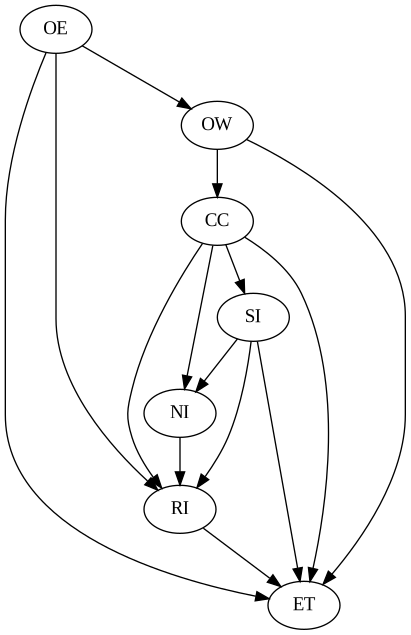

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import Image

# Create the graph from defined edges
edges = [
    ('OE','OW'),{'NI','SI'},
    ('OE','RI'),('CC','RI'),('RI','ET'),('CC','NI'),
    ('OW','CC'),('CC','SI'),('NI','RI'),('SI','RI'),
    ('OE','ET'),('OW','ET'),('CC','ET'),('SI', 'ET')
]
graph = nx.DiGraph(edges)

# Use pygraphviz (via networkx) for layout and saving to png
p = nx.drawing.nx_pydot.to_pydot(graph)
p.write_png('causal_graph.png')

# Display the saved image
Image('causal_graph.png')

In [ ]:
from dowhy import CausalModel, gcm
import pandas as pd

In [ ]:
from dowhy import gcm
causal_model = gcm.StructuralCausalModel(causal_graph)

In [ ]:
# Set causal mechanisms for each node
causal_model.set_causal_mechanism('OE', gcm.EmpiricalDistribution())
causal_model.set_causal_mechanism('CC', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('RI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('NI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('SI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('OW', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('ET', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))

# Now fit the model , Fitting the SCM to the data
gcm.fit(causal_model, df)



Fitting causal mechanism of node CC: 100%|██████████| 7/7 [00:00<00:00, 167.36it/s]


Test permutations of given graph: 100%|██████████| 50/50 [00:49<00:00,  1.01it/s]


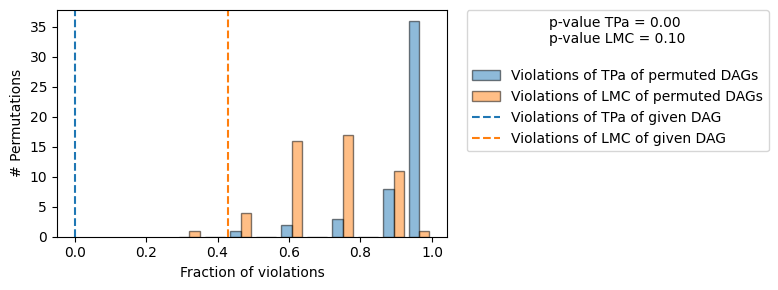

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:

==== Evaluation of Causal Mechanisms ====
The used evaluation metrics are:
- KL divergence (only for root-nodes): Evaluates the divergence between the generated and the observed distribution.
- Mean Squared Error (MSE): Evaluates the average squared differences between the observed values and the conditional expectation of the causal mechanisms.
- Normalized MSE (NMSE): The MSE normalized by the standard deviation for better comparison.
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
- F1 score (only for categorical non-root nodes): The harmonic mean of the precision and recall indicating the goodness of the under

In [ ]:
print(gcm.evaluate_causal_model(causal_model, df))

To find a DAG that is informative and not rejected for Eclipse, we must systematically find which conditional independencies actually hold in your data.

I will create a script to analyze the conditional independencies (partial correlations) among your variables (PR, CC, ET, OE, OW, RI, SI). We will start with a fully connected DAG (which has 0 LMC violations but is uninformative) and remove only the edges that represent true conditional independencies in the data. This guarantees that any Local Markov Condition we test will not be violated, keeping the DAG both informative and not rejected.

In [ ]:
import pandas as pd
import networkx as nx
import dowhy.gcm as gcm
from dowhy.gcm.falsify import falsify_graph

# 1. Load the data
url = "https://raw.githubusercontent.com/ReshmiMaulik/Understanding-Developer-Interaction/main/Data/workingdataO.csv"
df1 = pd.read_csv(url, sep=",")

# Rename 'Pr' to 'PR' to match the graph nodes
df = df.rename(columns={'Pr': 'PR'})

# Keep the columns that match our graph nodes
# We will use the main variables defined in the graph: PR, CC, ET, OE, OW, RI, SI
selected_cols = ['PR', 'CC', 'ET', 'OE', 'OW', 'RI', 'SI','NI']
data_subset = df[selected_cols].dropna().copy()

# 2. Define the causal graph structure
edges = [
    ('OE','OW'),{'NI','SI'}, ('SI', 'ET'),
    ('OE','RI'),('CC','RI'),('RI','ET'),('CC','NI'),
    ('OW','CC'),('CC','SI'),('NI','RI'),('SI','RI'),
    ('OE','ET'),('OW','ET'),('CC','ET')
]
causal_graph = nx.DiGraph(edges)

# 3. Perform permutation test using dowhy.gcm.falsify.falsify_graph
#print("Running graph falsification test...")
#falsification_results = falsify_graph(causal_graph, data_subset)
#print(falsification_results)

In [ ]:
# Set causal mechanisms for each node
causal_model.set_causal_mechanism('OE', gcm.EmpiricalDistribution())
causal_model.set_causal_mechanism('CC', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('RI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('NI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('SI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('OW', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('ET', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))

# Now fit the model , Fitting the SCM to the data
gcm.fit(causal_model, df1)



Fitting causal mechanism of node CC: 100%|██████████| 7/7 [00:00<00:00, 143.06it/s]


Test permutations of given graph: 100%|██████████| 50/50 [00:54<00:00,  1.10s/it]


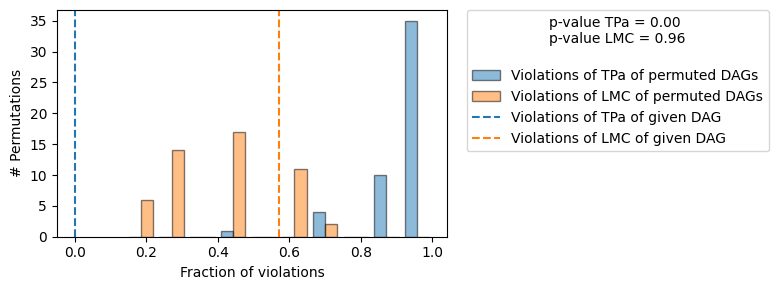

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:

==== Evaluation of Causal Mechanisms ====
The used evaluation metrics are:
- KL divergence (only for root-nodes): Evaluates the divergence between the generated and the observed distribution.
- Mean Squared Error (MSE): Evaluates the average squared differences between the observed values and the conditional expectation of the causal mechanisms.
- Normalized MSE (NMSE): The MSE normalized by the standard deviation for better comparison.
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
- F1 score (only for categorical non-root nodes): The harmonic mean of the precision and recall indicating the goodness of the under

In [ ]:
print(gcm.evaluate_causal_model(causal_model, df1))

In [ ]:
# fINAL gRAPH
import pandas as pd
import networkx as nx
import dowhy.gcm as gcm
from dowhy.gcm.falsify import falsify_graph

# 1. Load the correct data file which has all required columns
url = ("https://raw.githubusercontent.com/ReshmiMaulik/"
       "Causal_Inference-for-Openstack/main/workingdata_eclipse_newET.csv")
raw = pd.read_csv(url)
print(raw.shape)          # expected: (13248, ...)

# 2. Keep only usable bugs (resolution and creation dates present, not a duplicate record)
df = raw[raw['usable'].astype(str) == 'True'].copy()
print(len(df))            # expected: 12624


# Rename 'Pr' to 'PR' if needed, though PR is not in selected_cols
#df1 = df1.rename(columns={'ET_days': 'ET'})
df = df.rename(columns={
    'ET_days': 'ET',
    'Contributors': 'CC',
    'OwnerEngagement': 'OE',
    'OwnerWorkload': 'OW',
    'NewInteractions': 'NI',
    'SeasonedInteractions': 'SI',
    'RepeatedInteractions': 'RI',
})

# Ensure all required columns are in the dataframe
selected_cols = ['CC', 'ET', 'OE', 'OW', 'RI', 'SI', 'NI']
data_subset = df[selected_cols].dropna().copy()

# 2. Define the causal graph structure
edges = [
    ('OE', 'OW'),                              # owner variables
    ('OW', 'CC'),
    ('CC', 'NI'), ('CC', 'SI'), ('CC', 'RI'),  # sum identity: NI + FI + SI + RI = CC(CC-1)/2
    ('OE', 'NI'), ('OW', 'NI'),                # owner influence on who joins
    ('OW', 'SI'),
    ('OE', 'RI'), ('OW', 'RI'),
    ('NI', 'SI'), ('NI', 'RI'), ('SI', 'RI'),  # interaction types compete for a fixed number of pairs
    ('RI', 'ET'),                              # effect of interest (RQ1)
    ('CC', 'ET'), ('OW', 'ET'), ('OE', 'ET')
]
causal_graph = nx.DiGraph(edges)

# 3. Perform permutation test using dowhy.gcm.falsify.falsify_graph
print("Running graph falsification test...")
falsification_results = falsify_graph(causal_graph, data_subset)
print(falsification_results)

(13248, 21)
12624
Running graph falsification test...


Test permutations of given graph:   0%|          | 0/20 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Test permutations of given graph: 100%|██████████| 20/20 [16:44<00:00, 50.22s/it]

+-------------------------------------------------------------------------------------------------------+
|                                         Falsification Summary                                         |
+-------------------------------------------------------------------------------------------------------+
| The given DAG is informative because 0 / 20 of the permutations lie in the Markov                     |
| equivalence class of the given DAG (p-value: 0.00).                                                   |
| The given DAG violates 3/4 LMCs and is better than 35.0% of the permuted DAGs (p-value: 0.65).        |
| Based on the provided significance level (0.05) and because the DAG is informative,                   |
| we reject the DAG.                                                                                    |
+-------------------------------------------------------------------------------------------------------+


In [ ]:
# 4. Analysis data frame: covariates on the log scale, as in the paper's specification
data = df[['issue_id', 'ET', 'RI', 'SI', 'NI', 'CC', 'OE', 'OW']].copy()
data['CC'] = np.log(data['CC'])
data['OE'] = np.log1p(data['OE'])
data['OW'] = np.log1p(data['OW'])
data['NI'] = np.log1p(data['NI'])

data.head()

,issue_id,ET,RI,SI,NI,CC,OE,OW
0,15,78.067986,0,0,1.945910,1.386294,4.219508,5.916202
1,17,553.083010,3,0,1.945910,1.945910,1.386294,3.135494
2,227,215.268831,1,0,0.693147,1.386294,6.854355,7.778211
3,246,8.630058,3,3,1.386294,1.945910,6.854355,7.778211
4,714,3.985648,0,0,2.397895,1.791759,6.854355,7.778211


In [ ]:
df

,issue_id,ET,Priority,Interest,CC,ExternalContributors,CommunityInterest,OW,OE,OwnerSpectrum,...,NI,FreshInteractions,SI,RI,TotalDistinctEdges,TotalEdges,creation_date_source,ET_old_hours,usable,duplicate_of
0,15,78.067986,4,19,4,3,8,370,67,56,...,6,0,0,0,6,6,recorded,5552.9869,True,NaN
1,17,553.083010,4,69,7,7,69,22,3,3,...,6,12,0,3,18,21,recovered,18153.1039,True,NaN
2,227,215.268831,1,22,4,4,22,2387,947,931,...,1,4,0,1,5,6,recorded,8036.4122,True,NaN
3,246,8.630058,4,49,7,7,49,2387,947,931,...,3,12,3,3,18,21,recorded,45289.5589,True,NaN
4,714,3.985648,5,33,6,6,33,2387,947,931,...,10,5,0,0,15,15,recovered,7442.6375,True,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13243,468934,76.178022,3,12,5,5,9,4,4,1,...,6,4,0,0,10,10,recovered,2758.8592,True,NaN
13244,469014,0.957406,3,12,4,4,12,48,23,14,...,0,0,1,5,1,6,recovered,476.0944,True,NaN
13245,469083,0.049214,3,13,4,4,9,51,19,12,...,0,0,2,4,2,6,recovered,312.7228,True,NaN
13246,469087,4.051412,3,17,3,3,11,38,49,25,...,0,0,0,3,0,3,recorded,239.0242,True,NaN


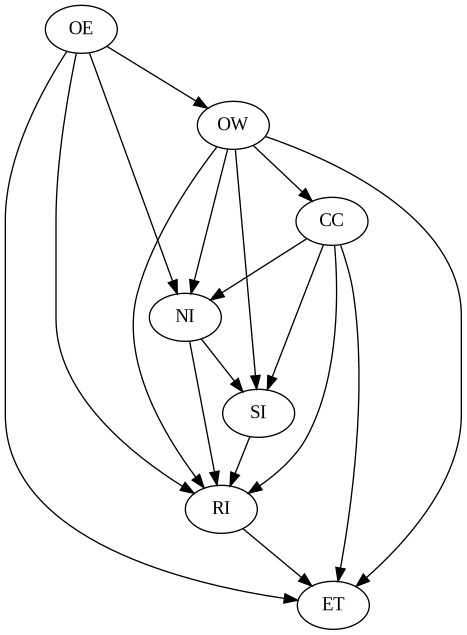

In [ ]:
from IPython.display import Image
import networkx as nx

# Use pygraphviz (via networkx) for layout and saving to png
# Changed 'graph' to 'causal_graph' to match your defined graph variable
p = nx.drawing.nx_pydot.to_pydot(causal_graph)
p.write_png('causal_graph_F.png')

# Display the saved image
Image('causal_graph_F.png')

In [ ]:
# Set causal mechanisms for each node
causal_model.set_causal_mechanism('OE', gcm.EmpiricalDistribution())
causal_model.set_causal_mechanism('CC', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('RI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('NI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('SI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('OW', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('ET', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))

# Now fit the model , Fitting the SCM to the data
gcm.fit(causal_model, df1)


Fitting causal mechanism of node ET: 100%|██████████| 7/7 [00:00<00:00, 95.10it/s]


Test permutations of given graph:   4%|▍         | 2/50 [00:03<01:29,  1.86s/it]/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Test permutations of given graph: 100%|██████████| 50/50 [00:50<00:00,  1.01s/it]


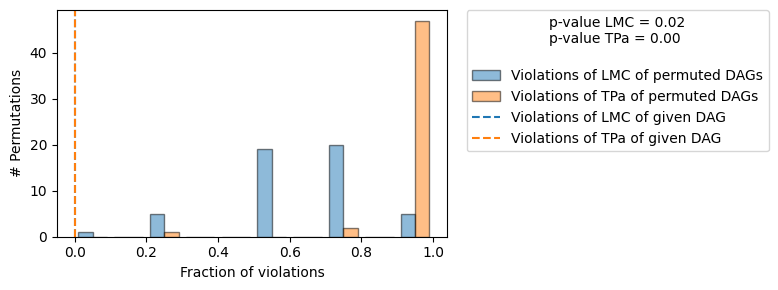

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:

==== Evaluation of Causal Mechanisms ====
The used evaluation metrics are:
- KL divergence (only for root-nodes): Evaluates the divergence between the generated and the observed distribution.
- Mean Squared Error (MSE): Evaluates the average squared differences between the observed values and the conditional expectation of the causal mechanisms.
- Normalized MSE (NMSE): The MSE normalized by the standard deviation for better comparison.
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
- F1 score (only for categorical non-root nodes): The harmonic mean of the precision and recall indicating the goodness of the under

In [ ]:
print(gcm.evaluate_causal_model(causal_model, df1))

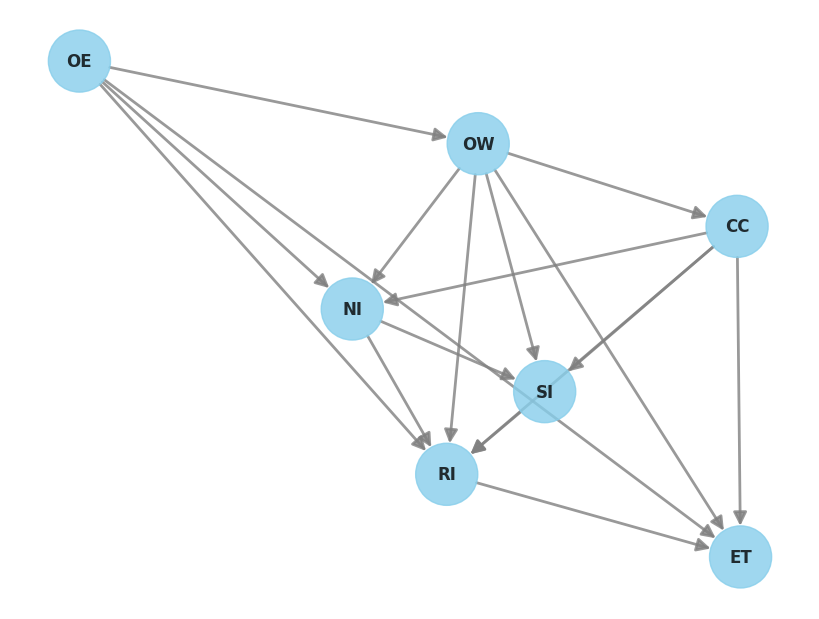

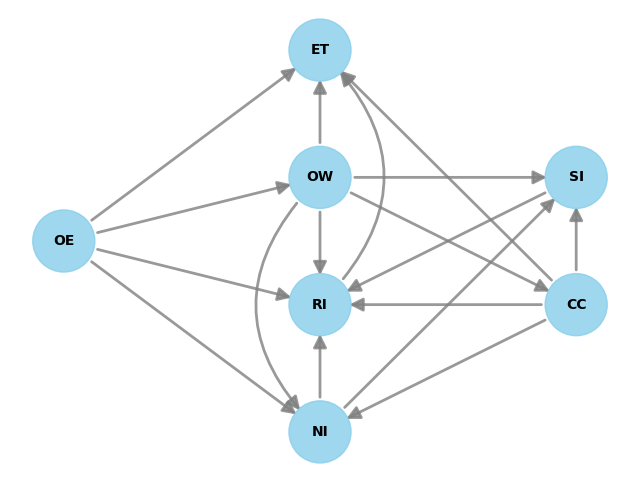

In [ ]:
model=CausalModel(
        data = df,
        treatment='RI',
        outcome='ET',
        graph=causal_graph,  # Pass the causal_graph variable directly
        instruments=['CC', 'OE', 'OW']
        )
model.view_model(layout="dot")
model.view_model(file_name="causal_model.png")

In [ ]:
identified_estimand = model.identify_effect()
print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d                  
─────(E[ET|OE,CC,OW])
d[RI]                
Estimand assumption 1, Unconfoundedness: If U→{RI} and U→ET then P(ET|RI,OE,CC,OW,U) = P(ET|RI,OE,CC,OW)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
  d                  
─────(E[ET|CC,OW,OE])
d[RI]                
Estimand assumption 1, Unconfoundedness: If U→{RI} and U→ET then P(ET|RI,CC,OW,OE,U) = P(ET|RI,CC,OW,OE)



In [ ]:
estimate= model.estimate_effect(
 identified_estimand,
 method_name='backdoor.linear_regression',
 confidence_intervals=True,
  test_significance=True
)

print(f'Estimate of causal effect: {estimate}')

Estimate of causal effect: *** Causal Estimate ***

## Identified estimand
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d                  
─────(E[ET|OE,CC,OW])
d[RI]                
Estimand assumption 1, Unconfoundedness: If U→{RI} and U→ET then P(ET|RI,OE,CC,OW,U) = P(ET|RI,OE,CC,OW)

## Realized estimand
b: ET~RI+OE+CC+OW
Target units: ate

## Estimate
Mean value: -0.1721225047179189
p-value: 2.65e-17 (significant at alpha=0.05; H0: treatment has no causal effect on outcome)
95.0% confidence interval: [[-0.212 -0.132]]



Estimand name: backdoor
Estimand expression:
  d                  
─────(E[ET|OE,CC,OW])
d[RI]                
Estimand assumption 1, Unconfoundedness: If U→{RI} and U→ET then P(ET|RI,OE,CC,OW,U) = P(ET|RI,OE,CC,OW)

## Realized estimand
b: ET~RI+OE+CC+OW
Target units: ate

## Estimate
Mean value: -10.220227869034716
p-value: 9.84e-14 (significant at alpha=0.05; H0: treatment has no causal effect on outcome)
95.0% confidence interval: [[-12.909  -7.532]]

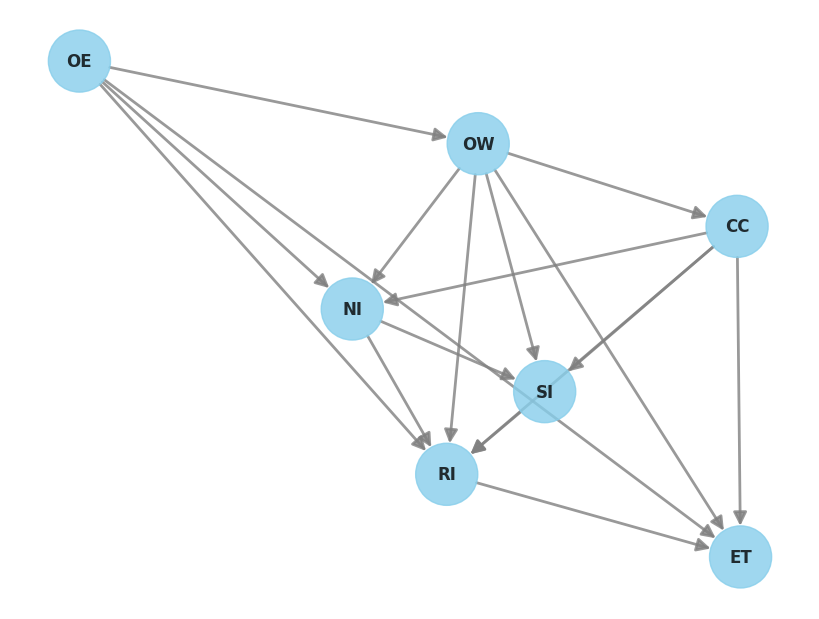

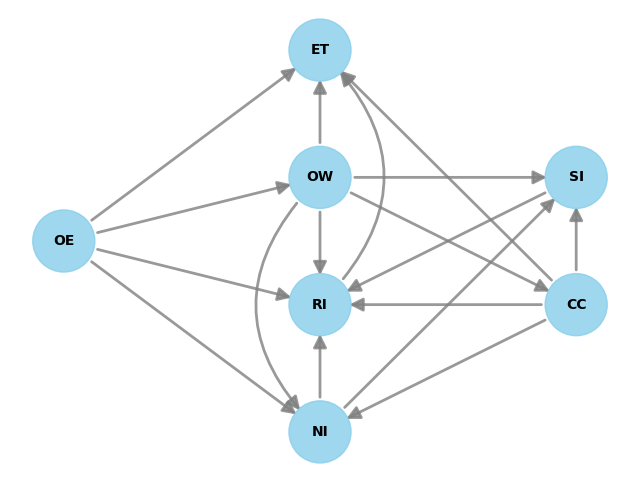

In [ ]:
# For SI
model=CausalModel(
        data = df,
        treatment='SI',
        outcome='ET',
        graph=causal_graph,  # Pass the causal_graph variable directly
        instruments=['CC', 'NI', 'OW']
        )
model.view_model(layout="dot")
model.view_model(file_name="causal_model.png")

In [ ]:
identified_estimand = model.identify_effect()
print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d                  
─────(E[ET|NI,CC,OW])
d[SI]                
Estimand assumption 1, Unconfoundedness: If U→{SI} and U→ET then P(ET|SI,NI,CC,OW,U) = P(ET|SI,NI,CC,OW)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
  d                  
─────(E[ET|NI,CC,OW])
d[SI]                
Estimand assumption 1, Unconfoundedness: If U→{SI} and U→ET then P(ET|SI,NI,CC,OW,U) = P(ET|SI,NI,CC,OW)



In [ ]:
estimate= model.estimate_effect(
 identified_estimand,
 method_name='backdoor.linear_regression',
 confidence_intervals=True,
  test_significance=True
)

print(f'Estimate of causal effect: {estimate}')

Estimate of causal effect: *** Causal Estimate ***

## Identified estimand
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d                  
─────(E[ET|NI,CC,OW])
d[SI]                
Estimand assumption 1, Unconfoundedness: If U→{SI} and U→ET then P(ET|SI,NI,CC,OW,U) = P(ET|SI,NI,CC,OW)

## Realized estimand
b: ET~SI+NI+CC+OW
Target units: ate

## Estimate
Mean value: -0.45048484463114846
p-value: 3.37e-09 (significant at alpha=0.05; H0: treatment has no causal effect on outcome)
95.0% confidence interval: [[-0.6   -0.301]]



In [ ]:
import statsmodels.api as sm
est = model.estimate_effect(identified_estimand,
        method_name='backdoor.generalized_linear_model',
        method_params={'glm_family': sm.families.Poisson()},
        control_value=0, treatment_value=1, effect_modifiers=[])

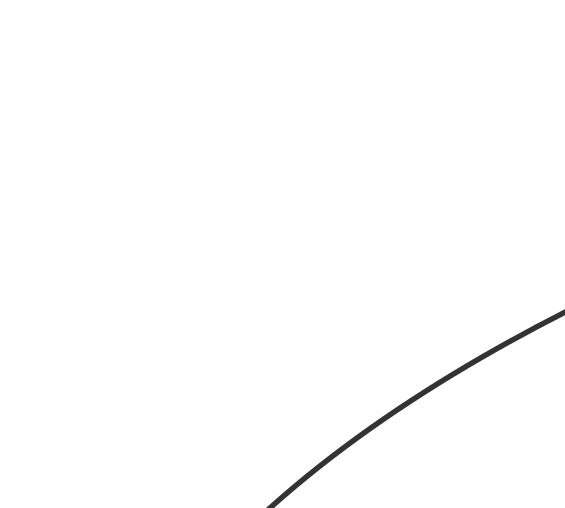

In [ ]:
import graphviz

dot_src = """
digraph Figure5 {
  graph [rankdir=TB, dpi=300, fontname="Helvetica", nodesep=0.55, ranksep=0.6, bgcolor="white", pad=0.2];
  node  [fontname="Helvetica", fontsize=12, shape=ellipse, style=filled, fillcolor="#F2F2F2", color="#555555", penwidth=1.2];
  edge  [color="#333333", penwidth=1.3, arrowsize=0.75];

  OE [label="OE\\nOwner engagement"];
  OW [label="OW\\nOwner workload"];
  CC [label="CC\\nContributors"];
  NI [label="NI\\nNew interactions"];
  SI [label="SI\\nSeasoned interactions", shape=box, fillcolor="#DCE9F7", color="#2B6CB0"];
  RI [label="RI\\nRepeated interactions", shape=box, fillcolor="#DCE9F7", color="#2B6CB0"];
  ET [label="ET\\nResolution time", shape=box, style="rounded,filled", fillcolor="#DFF1E1", color="#2F855A", penwidth=1.6];

  {rank=same; OE;}
  {rank=same; OW;}
  {rank=same; CC;}
  {rank=same; NI; SI;}
  {rank=same; RI;}
  {rank=same; ET;}

  OE -> OW;
  OW -> CC;
  CC -> NI; CC -> SI; CC -> RI;
  OW -> SI;
  OE -> RI;
  NI -> RI; SI -> RI;
  RI -> ET [color="#2B6CB0", penwidth=2.2];
  CC -> ET; OW -> ET; OE -> ET;
}
"""

graphviz.Source(dot_src)

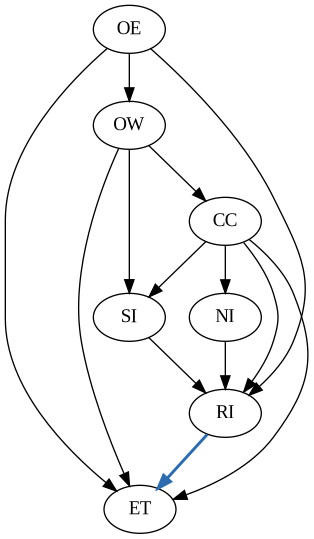

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import Image

# Create the graph from correctly formatted Python tuples
edges = [
    ('OE', 'OW'),
    ('OW', 'CC'),
    ('CC', 'NI'), ('CC', 'SI'), ('CC', 'RI'),
    ('OW', 'SI'),
    ('OE', 'RI'),
    ('NI', 'RI'), ('SI', 'RI'),
    ('RI', 'ET'),
    ('CC', 'ET'), ('OW', 'ET'), ('OE', 'ET')
]
graph = nx.DiGraph(edges)

# Use pygraphviz (via networkx) for layout and saving to png
p = nx.drawing.nx_pydot.to_pydot(graph)

# Customize edge colors matching your configuration
for edge in p.get_edges():
    if edge.get_source() == 'RI' and edge.get_destination() == 'ET':
        edge.set_color('#2B6CB0')
        edge.set_penwidth(2.2)

p.write_png('causal_graph.png')

# Display the saved image
Image('causal_graph.png')

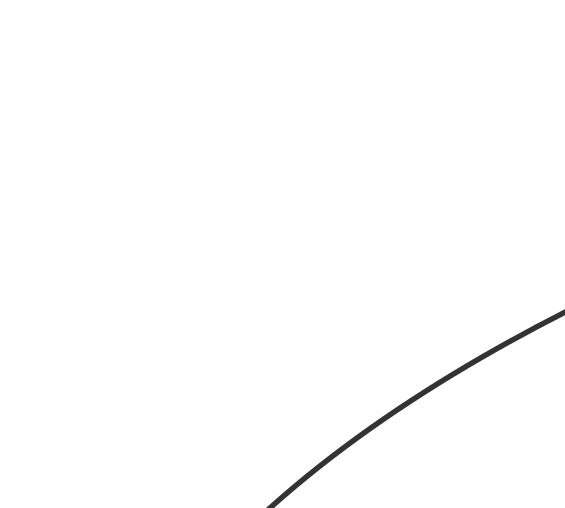

In [ ]:
import graphviz
graphviz.Source(dot_src)

In [ ]:
# fINAL gRAPH for Openstack
import pandas as pd
import networkx as nx
import dowhy.gcm as gcm
from dowhy.gcm.falsify import falsify_graph

# 1. Load the correct data file which has all required columns
url = ("https://raw.githubusercontent.com/ReshmiMaulik/"
       "Causal_Inference-for-Openstack/main/workingdata_openstack_newET.csv")
raw = pd.read_csv(url)
print(raw.shape)          # expected: (13248, ...)

# 2. Keep only usable bugs (resolution and creation dates present, not a duplicate record)
df = raw[raw['usable'].astype(str) == 'True'].copy()
print(len(df))            # expected: 12624


# Rename 'Pr' to 'PR' if needed, though PR is not in selected_cols
#df1 = df1.rename(columns={'ET_days': 'ET'})
df = df.rename(columns={
    'ET_days': 'ET',
    'Contributors': 'CC',
    'OwnerEngagement': 'OE',
    'OwnerWorkload': 'OW',
    'NewInteractions': 'NI',
    'SeasonedInteractions': 'SI',
    'RepeatedInteractions': 'RI',
})

# Ensure all required columns are in the dataframe
selected_cols = ['CC', 'ET', 'OE', 'OW', 'RI', 'SI', 'NI']
data_subset = df[selected_cols].dropna().copy()

# 2. Define the causal graph structure
edges = [
    ('OE', 'OW'),                              # owner variables
    ('OW', 'CC'),
    ('CC', 'NI'), ('CC', 'SI'), ('CC', 'RI'),  # sum identity: NI + FI + SI + RI = CC(CC-1)/2
    ('OE', 'NI'), ('OW', 'NI'),                # owner influence on who joins
    ('OW', 'SI'),
    ('OE', 'RI'), ('OW', 'RI'),
    ('NI', 'SI'), ('NI', 'RI'), ('SI', 'RI'),  # interaction types compete for a fixed number of pairs
    ('RI', 'ET'),                              # effect of interest (RQ1)
    ('CC', 'ET'), ('OW', 'ET'), ('OE', 'ET')
]
causal_graph = nx.DiGraph(edges)

# 3. Perform permutation test using dowhy.gcm.falsify.falsify_graph
print("Running graph falsification test...")
falsification_results = falsify_graph(causal_graph, data_subset)
print(falsification_results)

(25531, 19)
25321
Running graph falsification test...


Test permutations of given graph:   0%|          | 0/20 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Test permutations of given graph: 100%|██████████| 20/20 [18:22<00:00, 55.12s/it]

+-------------------------------------------------------------------------------------------------------+
|                                         Falsification Summary                                         |
+-------------------------------------------------------------------------------------------------------+
| The given DAG is informative because 0 / 20 of the permutations lie in the Markov                     |
| equivalence class of the given DAG (p-value: 0.00).                                                   |
| The given DAG violates 1/4 LMCs and is better than 85.0% of the permuted DAGs (p-value: 0.15).        |
| Based on the provided significance level (0.05) and because the DAG is informative,                   |
| we reject the DAG.                                                                                    |
+-------------------------------------------------------------------------------------------------------+


In [ ]:
# 4. Analysis data frame: covariates on the log scale, as in the paper's specification
data = df[['issue_id', 'ET', 'RI', 'SI', 'NI', 'CC', 'OE', 'OW']].copy()
data['CC'] = np.log(data['CC'])
data['OE'] = np.log1p(data['OE'])
data['OW'] = np.log1p(data['OW'])
data['NI'] = np.log1p(data['NI'])

data.head()

,issue_id,ET,RI,SI,NI,CC,OE,OW
0,4,0.453970,0,0,1.386294,1.098612,5.736572,4.043051
1,11,3.003241,0,0,0.693147,1.098612,7.715570,5.204007
2,14,0.004005,2,1,0.000000,1.098612,5.736572,4.043051
3,31,49.651007,0,0,0.693147,1.098612,0.000000,9.668082
4,32,7.286111,2,1,0.000000,1.386294,5.908083,4.219508


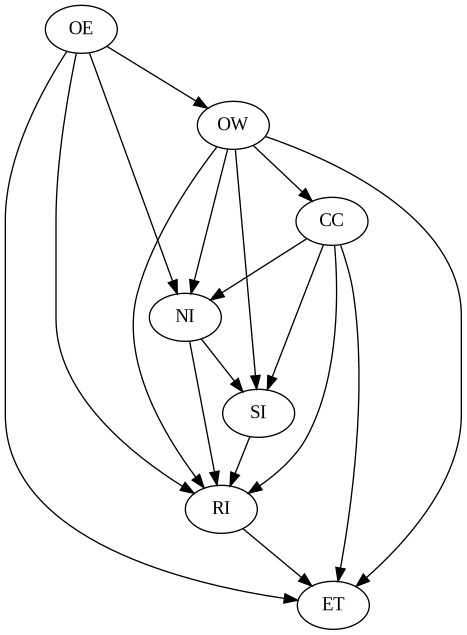

In [ ]:
from IPython.display import Image
import networkx as nx

# Use pygraphviz (via networkx) for layout and saving to png
# Changed 'graph' to 'causal_graph' to match your defined graph variable
p = nx.drawing.nx_pydot.to_pydot(causal_graph)
p.write_png('causal_graph_F.png')

# Display the saved image
Image('causal_graph_F.png')

In [ ]:
# Set causal mechanisms for each node
causal_model.set_causal_mechanism('OE', gcm.EmpiricalDistribution())
causal_model.set_causal_mechanism('CC', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('RI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('NI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('SI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('OW', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('ET', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))

# Now fit the model , Fitting the SCM to the data
gcm.fit(causal_model, df)


Fitting causal mechanism of node ET: 100%|██████████| 7/7 [00:00<00:00, 114.91it/s]


Test permutations of given graph:  12%|█▏        | 6/50 [00:06<00:43,  1.00it/s]/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Test permutations of given graph: 100%|██████████| 50/50 [00:48<00:00,  1.03it/s]


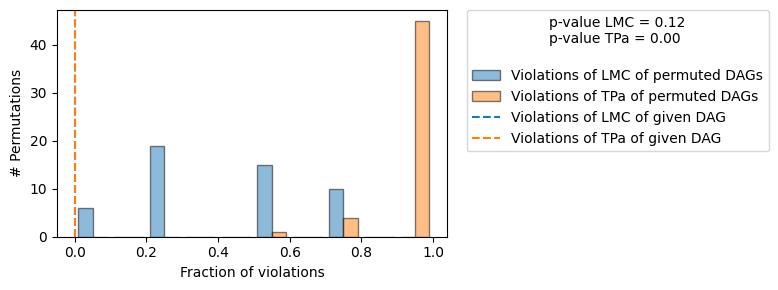

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:

==== Evaluation of Causal Mechanisms ====
The used evaluation metrics are:
- KL divergence (only for root-nodes): Evaluates the divergence between the generated and the observed distribution.
- Mean Squared Error (MSE): Evaluates the average squared differences between the observed values and the conditional expectation of the causal mechanisms.
- Normalized MSE (NMSE): The MSE normalized by the standard deviation for better comparison.
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
- F1 score (only for categorical non-root nodes): The harmonic mean of the precision and recall indicating the goodness of the under

In [ ]:
print(gcm.evaluate_causal_model(causal_model, df))

The setup used to evaluate the performance of your causal mechanisms, their invertibility assumptions, the overall average KL divergence, and the graph structure (using the 50 random permutations shown in your logs) is powered by DoWhy's Graphical Causal Model (GCM) framework.

Specifically, the function gcm.evaluate_causal_model(causal_model, df) performs these checks. It evaluates:

Causal Mechanisms (using MSE, $R^2$$R^2$, and CRPS): To test how well the chosen structural equations fit your data.
Generated Distribution (KL Divergence): To compare the joint distribution generated by the fitted SCM with the observed dataset.
Causal Graph Structure (via falsify_graph): To check the Local Markov Conditions (LMCs) against permuted graphs to test if the DAG is statistically rejected.


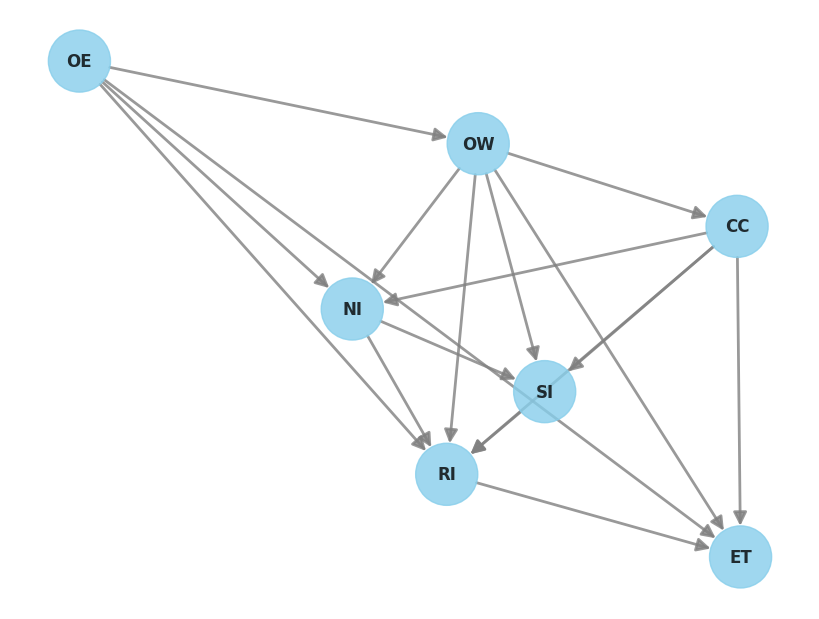

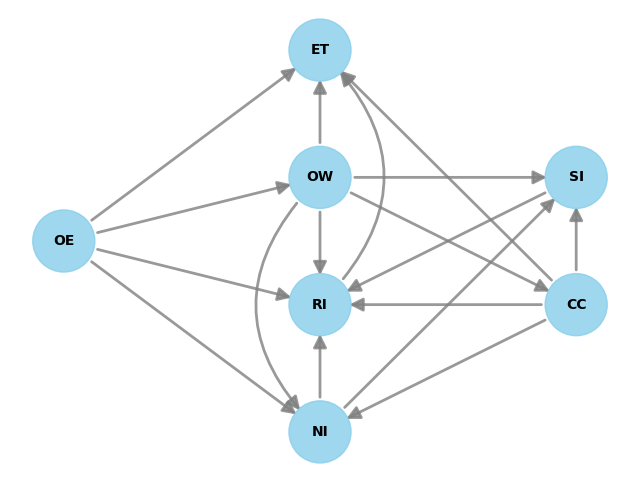

In [ ]:
model=CausalModel(
        data = data,
        treatment='RI',
        outcome='ET',
        graph=causal_graph,  # Pass the causal_graph variable directly
        instruments=['CC', 'OE', 'OW']
        )
model.view_model(layout="dot")
model.view_model(file_name="causal_model.png")

In [ ]:
identified_estimand = model.identify_effect()
print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d                  
─────(E[ET|OE,CC,OW])
d[RI]                
Estimand assumption 1, Unconfoundedness: If U→{RI} and U→ET then P(ET|RI,OE,CC,OW,U) = P(ET|RI,OE,CC,OW)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
  d                  
─────(E[ET|CC,OW,OE])
d[RI]                
Estimand assumption 1, Unconfoundedness: If U→{RI} and U→ET then P(ET|RI,CC,OW,OE,U) = P(ET|RI,CC,OW,OE)



In [ ]:
estimate= model.estimate_effect(
 identified_estimand,
 method_name='backdoor.linear_regression',
 confidence_intervals=True,
  test_significance=True
)

print(f'Estimate of causal effect: {estimate}')

Estimate of causal effect: *** Causal Estimate ***

## Identified estimand
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d                  
─────(E[ET|OE,CC,OW])
d[RI]                
Estimand assumption 1, Unconfoundedness: If U→{RI} and U→ET then P(ET|RI,OE,CC,OW,U) = P(ET|RI,OE,CC,OW)

## Realized estimand
b: ET~RI+OE+CC+OW
Target units: ate

## Estimate
Mean value: -0.4641778690477594
p-value: 4.67e-19 (significant at alpha=0.05; H0: treatment has no causal effect on outcome)
95.0% confidence interval: [[-0.566 -0.362]]



In [ ]:
import statsmodels.formula.api as smf
fit = smf.ols('ET ~ RI + OE + CC + OW', data).fit(cov_type='HC1')
print(fit.params['RI'], fit.conf_int().loc['RI'].values, fit.pvalues['RI'])

-0.46417786904775465 [-0.735 -0.193] 0.0007865996415236283


Causal inference of SI on ET for OpenStack

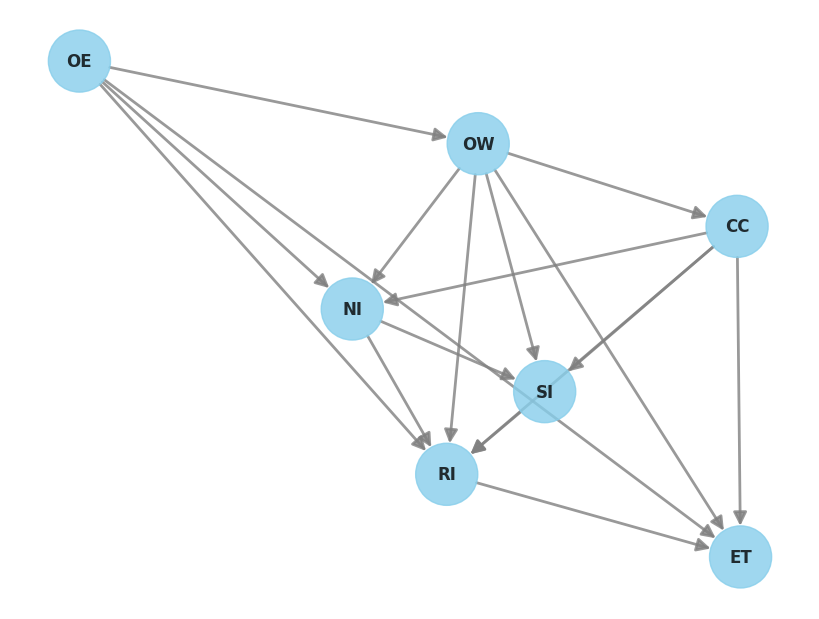

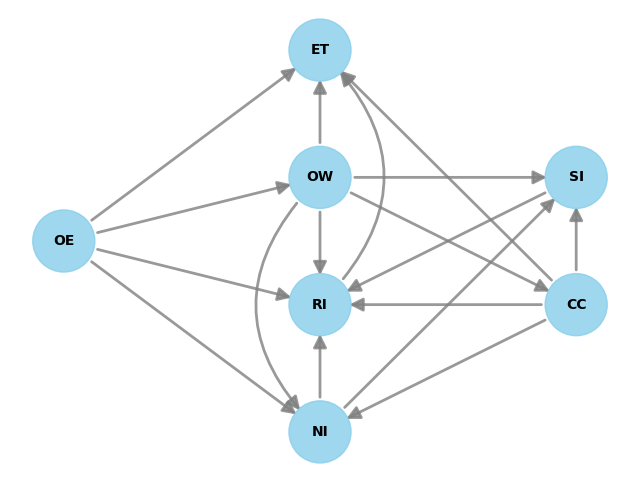

In [ ]:
model=CausalModel(
        data = df,
        treatment='SI',
        outcome='ET',
        graph=causal_graph,  # Pass the causal_graph variable directly
        instruments=['CC', 'OE', 'OW']
        )
model.view_model(layout="dot")
model.view_model(file_name="causal_model.png")

In [ ]:
identified_estimand = model.identify_effect()
print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d                  
─────(E[ET|NI,CC,OW])
d[SI]                
Estimand assumption 1, Unconfoundedness: If U→{SI} and U→ET then P(ET|SI,NI,CC,OW,U) = P(ET|SI,NI,CC,OW)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
  d                  
─────(E[ET|NI,CC,OW])
d[SI]                
Estimand assumption 1, Unconfoundedness: If U→{SI} and U→ET then P(ET|SI,NI,CC,OW,U) = P(ET|SI,NI,CC,OW)



In [ ]:
estimate= model.estimate_effect(
 identified_estimand,
 method_name='backdoor.linear_regression',
 confidence_intervals=True,
  test_significance=True
)

print(f'Estimate of causal effect: {estimate}')

Estimate of causal effect: *** Causal Estimate ***

## Identified estimand
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d                  
─────(E[ET|NI,CC,OW])
d[SI]                
Estimand assumption 1, Unconfoundedness: If U→{SI} and U→ET then P(ET|SI,NI,CC,OW,U) = P(ET|SI,NI,CC,OW)

## Realized estimand
b: ET~SI+NI+CC+OW
Target units: ate

## Estimate
Mean value: 1.807918547246139
p-value: 2.23e-41 (significant at alpha=0.05; H0: treatment has no causal effect on outcome)
95.0% confidence interval: [[1.545 2.07 ]]

